# Urdu Fake News Detection, and the Dataset Artifacts Behind High Scores

Classifies Urdu news articles as **real** or **fake** with TF-IDF features and linear models, then checks *why* the models score the way they do.

**Dataset:** *Bend The Truth* (Amjad et al., 2020): 900 Urdu news articles in five domains. Real articles come from mainstream news sites; fake articles were written by professional journalists as **fake rewrites of the real articles**.

**Notebook outline**
1. Load and explore the corpus
2. Real/fake rewrite pairs, and pair-aware cross-validation
3. Model selection on two versions of the text: *raw* and *normalised* (typing artifacts removed)
4. Final evaluation on the held-out test set (used once per model)
5. Dataset artifacts: a single character predicts the label
6. What the deployed model learned, and saving it

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

from src.urdu_text import MODEL_PATH, load_corpus, urdu_letters_only

SEED = 42
SHOTS = Path("screenshots"); SHOTS.mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
COLORS = {"real": "#2563eb", "fake": "#dc2626"}

## 1. Load and explore

In [2]:
df = load_corpus()
train = df[df.split == "train"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
print(pd.crosstab(df.split, df.label, margins=True))
df[["split", "label", "category", "pair_id", "n_words"]].head()

label  fake  real  All
split                 
test    112   150  262
train   288   350  638
All     400   500  900


,split,label,category,pair_id,n_words
0,train,real,Business,train-bus1,446
1,train,real,Business,train-bus10,202
2,train,real,Business,train-bus11,136
3,train,real,Business,train-bus12,1532
4,train,real,Business,train-bus13,763


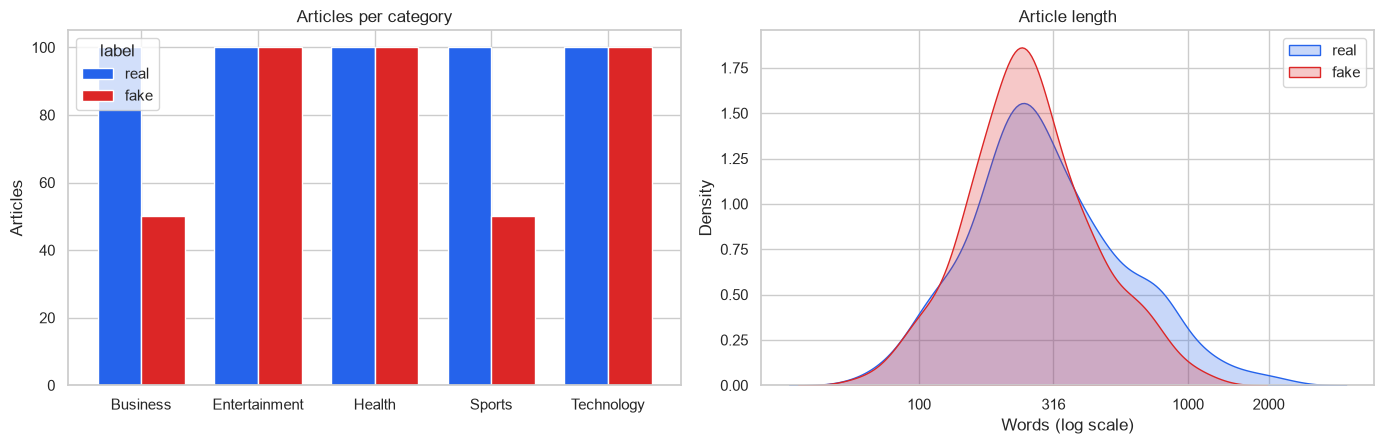

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ct = pd.crosstab(df.category, df.label)[["real", "fake"]]
ct.plot(kind="bar", ax=axes[0], color=[COLORS["real"], COLORS["fake"]], rot=0, width=0.75)
axes[0].set_title("Articles per category"); axes[0].set_xlabel(""); axes[0].set_ylabel("Articles")
for lab in ["real", "fake"]:
    sns.kdeplot(np.log10(df.loc[df.label == lab, "n_words"]), ax=axes[1], color=COLORS[lab], fill=True, alpha=0.25, label=lab)
axes[1].set_xticks([2, 2.5, 3, 3.3]); axes[1].set_xticklabels(["100", "316", "1000", "2000"])
axes[1].set_title("Article length"); axes[1].set_xlabel("Words (log scale)"); axes[1].legend()
plt.tight_layout(); plt.savefig(SHOTS / "dataset_overview.png", dpi=110); plt.show()

## 2. Real/fake rewrite pairs

Each fake article is a rewrite of a real article with the same file name (e.g. `bus12.txt` in both folders). If a real article were in the training data and its fake twin in the evaluation data, scores would be inflated. The official train/test split keeps pairs together, and the cross-validation below groups by `pair_id` to do the same.

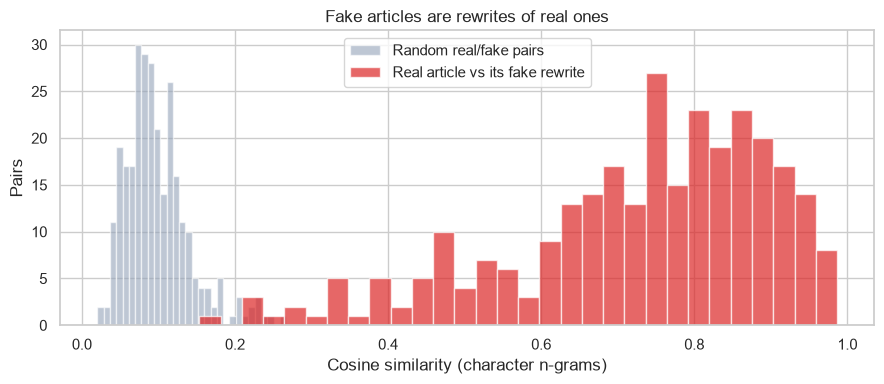

288 rewrite pairs in training. Median similarity 0.76 vs 0.09 for random pairs.
Test articles with a near-duplicate (>0.8) in training: 4 of 262


In [4]:
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2).fit(train.clean)
real = train[train.label == "real"].set_index("pair_id")
fake = train[train.label == "fake"].set_index("pair_id")
common = real.index.intersection(fake.index)
pair_sim = [cosine_similarity(vec.transform([real.loc[p, "clean"]]), vec.transform([fake.loc[p, "clean"]]))[0, 0] for p in common]
shuffled = np.random.default_rng(SEED).permutation(common)
rand_sim = [cosine_similarity(vec.transform([real.loc[a, "clean"]]), vec.transform([fake.loc[b, "clean"]]))[0, 0]
            for a, b in zip(common, shuffled) if a != b]
test_to_train = cosine_similarity(vec.transform(test.clean), vec.transform(train.clean)).max(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rand_sim, bins=30, alpha=0.6, label="Random real/fake pairs", color="#94a3b8")
ax.hist(pair_sim, bins=30, alpha=0.7, label="Real article vs its fake rewrite", color="#dc2626")
ax.set_xlabel("Cosine similarity (character n-grams)"); ax.set_ylabel("Pairs")
ax.set_title("Fake articles are rewrites of real ones"); ax.legend()
plt.tight_layout(); plt.savefig(SHOTS / "rewrite_pairs.png", dpi=110); plt.show()
print(f"{len(common)} rewrite pairs in training. Median similarity {np.median(pair_sim):.2f} vs {np.median(rand_sim):.2f} for random pairs.")
print(f"Test articles with a near-duplicate (>0.8) in training: {(test_to_train > 0.8).sum()} of {len(test)}")

## 3. Model selection on two versions of the text

* **Raw text:** every character exactly as typed (only whitespace is collapsed).
* **Normalised text:** removes typing artifacts. Arabic and Urdu forms of the same letter are unified (for example Arabic yeh `U+064A` becomes Urdu yeh `U+06CC`) and diacritics are removed. To a reader the text looks the same.

Six TF-IDF + linear-model pipelines are tuned with **5-fold GroupKFold on the training set only**, scored by macro F1.

In [5]:
groups = train.pair_id.str.replace("train-", "", regex=False)
cv = GroupKFold(n_splits=5)

def word_tfidf():
    return TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True)

def char_tfidf(analyzer="char", ngram_range=(1, 4)):
    return TfidfVectorizer(analyzer=analyzer, ngram_range=ngram_range, min_df=2, sublinear_tf=True, max_features=150000)

def candidates():
    return {
        "Majority class": (Pipeline([("tfidf", word_tfidf()), ("clf", DummyClassifier())]), {}),
        "Naive Bayes, word 1-2 grams": (Pipeline([("tfidf", word_tfidf()), ("clf", MultinomialNB())]), {"clf__alpha": [0.01, 0.1, 0.5]}),
        "LogReg, word 1-2 grams": (Pipeline([("tfidf", word_tfidf()), ("clf", LogisticRegression(max_iter=3000))]), {"clf__C": [1, 10, 100]}),
        "LogReg, char 1-4 grams": (Pipeline([("tfidf", char_tfidf()), ("clf", LogisticRegression(max_iter=3000))]), {"clf__C": [1, 10, 100]}),
        "Linear SVM, char 1-4 grams": (Pipeline([("tfidf", char_tfidf()), ("clf", LinearSVC())]), {"clf__C": [0.1, 1, 10]}),
        "Linear SVM, word + char": (Pipeline([("tfidf", FeatureUnion([("w", word_tfidf()), ("c", char_tfidf())])), ("clf", LinearSVC())]),
                                    {"clf__C": [0.1, 1, 10]}),
    }

rows, searches = [], {}
for text_col, text_name in [("raw", "Raw text"), ("clean", "Normalised text")]:
    for name, (pipe, grid) in candidates().items():
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=1).fit(train[text_col], train.y, groups=groups)
        searches[(text_col, name)] = gs
        rows.append({"Text": text_name, "Model": name, "CV macro F1": gs.best_score_,
                     "CV std": gs.cv_results_["std_test_score"][gs.best_index_], "Best params": gs.best_params_})
cv_results = pd.DataFrame(rows).sort_values(["Text", "CV macro F1"], ascending=[True, False]).reset_index(drop=True)
cv_results.round(3)

,Text,Model,CV macro F1,CV std,Best params
0,Normalised text,"LogReg, word 1-2 grams",0.788,0.030,{'clf__C': 100}
1,Normalised text,"Linear SVM, word + char",0.788,0.036,{'clf__C': 1}
2,Normalised text,"Linear SVM, char 1-4 grams",0.775,0.025,{'clf__C': 10}
3,Normalised text,"LogReg, char 1-4 grams",0.769,0.033,{'clf__C': 100}
4,Normalised text,"Naive Bayes, word 1-2 grams",0.661,0.015,{'clf__alpha': 0.01}
5,Normalised text,Majority class,0.354,0.001,{}
6,Raw text,"LogReg, char 1-4 grams",0.843,0.008,{'clf__C': 100}
7,Raw text,"Linear SVM, word + char",0.842,0.010,{'clf__C': 10}
8,Raw text,"Linear SVM, char 1-4 grams",0.837,0.008,{'clf__C': 10}
9,Raw text,"LogReg, word 1-2 grams",0.802,0.038,{'clf__C': 100}


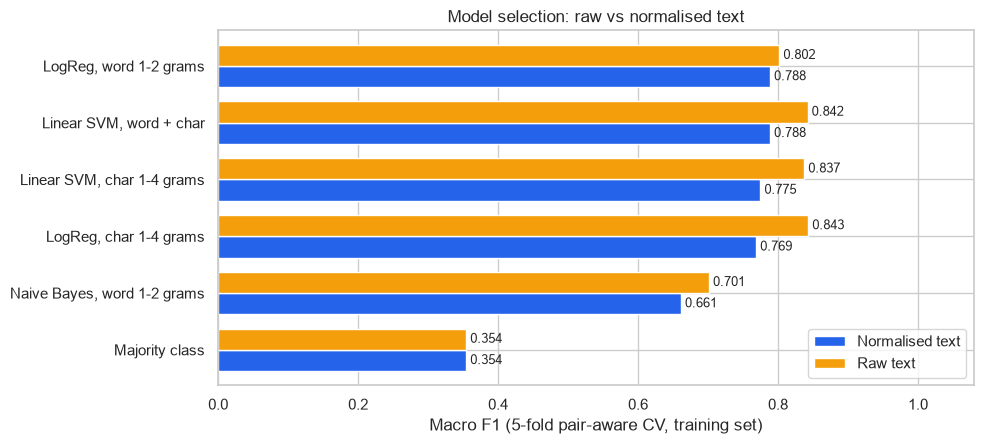

In [6]:
pivot = cv_results.pivot(index="Model", columns="Text", values="CV macro F1").sort_values("Normalised text")
ax = pivot[["Normalised text", "Raw text"]].plot(kind="barh", figsize=(10, 4.6), color=["#2563eb", "#f59e0b"], width=0.75)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.3f}" for v in c.datavalues], padding=3, fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel("Macro F1 (5-fold pair-aware CV, training set)"); ax.set_ylabel("")
ax.set_title("Model selection: raw vs normalised text"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(SHOTS / "model_selection.png", dpi=110); plt.show()

## 4. Final evaluation on the held-out test set

In [7]:
def best_for(text_col):
    sub = cv_results[cv_results.Text == ("Raw text" if text_col == "raw" else "Normalised text")]
    name = sub.sort_values("CV macro F1", ascending=False).Model.iloc[0]
    return name, searches[(text_col, name)].best_estimator_

final, metrics = {}, {}
pair_folds = list(GroupKFold(5).split(train.clean, train.y, groups))
for text_col in ["raw", "clean"]:
    name, est = best_for(text_col)
    model = CalibratedClassifierCV(est, cv=pair_folds, method="sigmoid").fit(train[text_col], train.y)
    proba = model.predict_proba(test[text_col])[:, 1]
    pred = (proba >= 0.5).astype(int)
    final[text_col] = model
    metrics[text_col] = {"model": name, "proba": proba, "pred": pred, "accuracy": accuracy_score(test.y, pred),
                         "macro_f1": f1_score(test.y, pred, average="macro"), "auc": roc_auc_score(test.y, proba)}
    print(f"{'Raw' if text_col == 'raw' else 'Normalised'} text -> {name}: accuracy {metrics[text_col]['accuracy']:.3f}, "
          f"macro F1 {metrics[text_col]['macro_f1']:.3f}, ROC AUC {metrics[text_col]['auc']:.3f}")

m = metrics["clean"]
print("\nDeployed model (normalised text):")
print(classification_report(test.y, m["pred"], target_names=["Real", "Fake"], digits=3))

Raw text -> LogReg, char 1-4 grams: accuracy 0.866, macro F1 0.860, ROC AUC 0.913


Normalised text -> LogReg, word 1-2 grams: accuracy 0.729, macro F1 0.717, ROC AUC 0.806

Deployed model (normalised text):
              precision    recall  f1-score   support

        Real      0.739     0.813     0.775       150
        Fake      0.711     0.616     0.660       112

    accuracy                          0.729       262
   macro avg      0.725     0.715     0.717       262
weighted avg      0.727     0.729     0.726       262



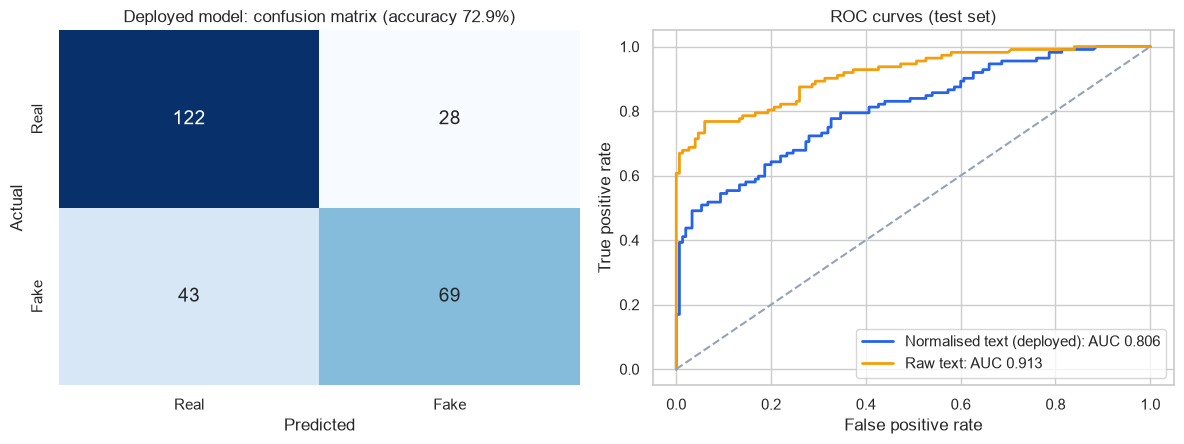

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cm = confusion_matrix(test.y, m["pred"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"], annot_kws={"size": 14})
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Deployed model: confusion matrix (accuracy {m['accuracy']:.1%})")
for col, label, color in [("clean", "Normalised text (deployed)", "#2563eb"), ("raw", "Raw text", "#f59e0b")]:
    fpr, tpr, _ = roc_curve(test.y, metrics[col]["proba"])
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{label}: AUC {metrics[col]['auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="#94a3b8")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves (test set)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(SHOTS / "test_results.png", dpi=110); plt.show()

## 5. Dataset artifacts: one character predicts the label

Raw text scores much higher than normalised text, even though the two look identical to a reader. The reason is **how the fake articles were typed**. Some journalists used a keyboard layout that produces the *Arabic* yeh (`U+064A`) instead of the *Urdu* yeh (`U+06CC`). The fakes also use fewer diacritics, Latin characters and punctuation marks than real articles copied from news websites.

In [9]:
def share(pattern):
    return df.groupby("label")["text"].apply(lambda t: t.str.contains(pattern, regex=True).mean())

def per_1000(pattern):
    return df.groupby("label")["text"].apply(lambda t: t.str.count(pattern).sum() / t.str.len().sum() * 1000)

AR_YEH = "ي"
artifacts = pd.DataFrame({
    "Articles containing Arabic yeh": share(AR_YEH),
    "Diacritics per 1,000 chars": per_1000("[ً-ٰٟ]"),
    "Latin letters per 1,000 chars": per_1000("[A-Za-z]"),
    "Punctuation per 1,000 chars": per_1000("[.,():۔،-]"),
}).T[["real", "fake"]]

rule = (~test.text.str.contains(AR_YEH)).map({True: 0, False: 1})
rule_acc = accuracy_score(test.y, rule)
letters_only = CalibratedClassifierCV(best_for("clean")[1], cv=pair_folds, method="sigmoid").fit(
    train.text.map(urdu_letters_only), train.y)
letters_acc = accuracy_score(test.y, letters_only.predict(test.text.map(urdu_letters_only)))
print(artifacts.round(3))
print(f"\nOne-character rule 'contains Arabic yeh -> fake': test accuracy {rule_acc:.3f}")

label                            real   fake
Articles containing Arabic yeh  0.012  0.308
Diacritics per 1,000 chars      2.468  1.649
Latin letters per 1,000 chars   5.788  2.209
Punctuation per 1,000 chars     8.407  5.764

One-character rule 'contains Arabic yeh -> fake': test accuracy 0.737


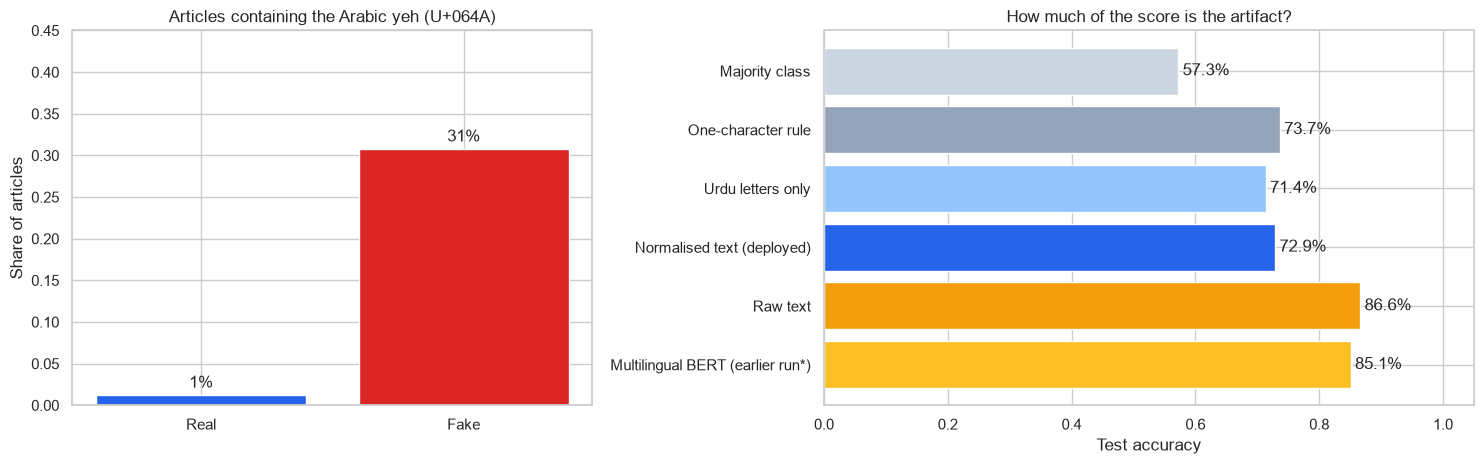

* BERT: earlier Colab run, not re-run here; it used the test set to choose the best epoch and kept the raw characters.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
ar = artifacts.loc["Articles containing Arabic yeh"]
bars = axes[0].bar(["Real", "Fake"], ar.values, color=[COLORS["real"], COLORS["fake"]])
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in ar.values], padding=3)
axes[0].set_ylim(0, 0.45); axes[0].set_ylabel("Share of articles")
axes[0].set_title("Articles containing the Arabic yeh (U+064A)")

summary_rows = [
    ("Majority class", accuracy_score(test.y, np.zeros_like(test.y)), "#cbd5e1"),
    ("One-character rule", rule_acc, "#94a3b8"),
    ("Urdu letters only", letters_acc, "#93c5fd"),
    ("Normalised text (deployed)", metrics["clean"]["accuracy"], "#2563eb"),
    ("Raw text", metrics["raw"]["accuracy"], "#f59e0b"),
    ("Multilingual BERT (earlier run*)", 0.851, "#fbbf24"),
]
labels, vals, cols = zip(*summary_rows)
b = axes[1].barh(labels, vals, color=cols)
axes[1].bar_label(b, labels=[f"{v:.1%}" for v in vals], padding=3)
axes[1].set_xlim(0, 1.05); axes[1].invert_yaxis(); axes[1].set_xlabel("Test accuracy")
axes[1].set_title("How much of the score is the artifact?")
plt.tight_layout(); plt.savefig(SHOTS / "artifacts.png", dpi=110); plt.show()
print("* BERT: earlier Colab run, not re-run here; it used the test set to choose the best epoch and kept the raw characters.")

**Takeaway.** A single invisible character predicts the label with about 74% accuracy, roughly as well as the artifact-free models. The raw-text model reaches about the same accuracy as the earlier BERT result, but much of that comes from typing differences rather than *what the article says*. The demo app therefore uses the **normalised-text model**. Its score is lower, but it reflects the content of the news, so it is more likely to carry over to real Urdu news.

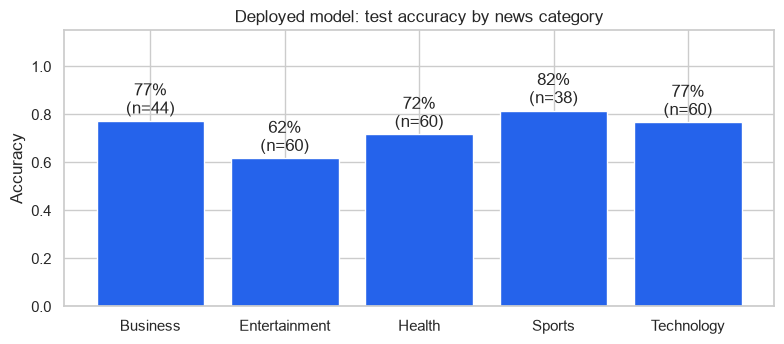

In [11]:
per_cat = (test.assign(pred=metrics["clean"]["pred"]).groupby("category")
           .apply(lambda g: pd.Series({"Articles": len(g), "Accuracy": accuracy_score(g.y, g.pred)}), include_groups=False))
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(per_cat.index, per_cat.Accuracy, color="#2563eb")
ax.bar_label(bars, labels=[f"{a:.0%}\n(n={int(n)})" for a, n in zip(per_cat.Accuracy, per_cat.Articles)], padding=2)
ax.set_ylim(0, 1.15); ax.set_ylabel("Accuracy"); ax.set_title("Deployed model: test accuracy by news category")
plt.tight_layout(); plt.savefig(SHOTS / "accuracy_by_category.png", dpi=110); plt.show()

## 6. What the deployed model learned, and saving it

In [12]:
interp = Pipeline([("tfidf", word_tfidf()), ("clf", LogisticRegression(max_iter=3000, C=10))]).fit(train.clean, train.y)
terms = np.array(interp.named_steps["tfidf"].get_feature_names_out())
coefs = interp.named_steps["clf"].coef_[0]
top = pd.DataFrame({"Top 'fake' terms": terms[np.argsort(coefs)[::-1][:15]],
                    "Top 'real' terms": terms[np.argsort(coefs)[:15]]})
top.to_csv("results/top_terms.csv", index=False, encoding="utf-8-sig")
top

,Top 'fake' terms,Top 'real' terms
0,اس لیے,دو
1,جو کہ,رائٹ
2,کہنا تھا,کے کاپی
3,وجہ سے,کاپی رائٹ
4,کر,کاپی
5,ہو,تصویر کے
6,ٹیلی فون,تین
7,ونڈو,تصویر
8,وجہ,نے کہا
9,انکا,تاہم


In [13]:
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(final["clean"], MODEL_PATH, compress=3)
summary = {
    "deployed_model": metrics["clean"]["model"] + " (normalised text)",
    "test_accuracy": round(metrics["clean"]["accuracy"], 4), "test_macro_f1": round(metrics["clean"]["macro_f1"], 4),
    "test_roc_auc": round(metrics["clean"]["auc"], 4),
    "raw_text_model": metrics["raw"]["model"], "raw_text_test_accuracy": round(metrics["raw"]["accuracy"], 4),
    "raw_text_test_macro_f1": round(metrics["raw"]["macro_f1"], 4), "raw_text_test_roc_auc": round(metrics["raw"]["auc"], 4),
    "one_character_rule_test_accuracy": round(rule_acc, 4), "urdu_letters_only_test_accuracy": round(letters_acc, 4),
    "earlier_bert_test_accuracy_reported": 0.851,
}
Path("results/summary.json").write_text(json.dumps(summary, indent=2))
cv_results.assign(**{"Best params": cv_results["Best params"].astype(str)}).round(4).to_csv("results/cv_results.csv", index=False)
artifacts.round(4).to_csv("results/artifacts.csv")
print(json.dumps(summary, indent=2))
print("Model size: %.1f MB" % (MODEL_PATH.stat().st_size / 1e6))

{
  "deployed_model": "LogReg, word 1-2 grams (normalised text)",
  "test_accuracy": 0.729,
  "test_macro_f1": 0.7174,
  "test_roc_auc": 0.8056,
  "raw_text_model": "LogReg, char 1-4 grams",
  "raw_text_test_accuracy": 0.8664,
  "raw_text_test_macro_f1": 0.8603,
  "raw_text_test_roc_auc": 0.9131,
  "one_character_rule_test_accuracy": 0.7366,
  "urdu_letters_only_test_accuracy": 0.7137,
  "earlier_bert_test_accuracy_reported": 0.851
}
Model size: 3.1 MB
